#HW0 - Introduction to Python

##Section 1: Assignment Setup


### Assignment Setup
Run the next cell to use the bundled files. Local Jupyter uses this repository; Google Colab clones it without requiring Google Drive access.


In [ ]:
from pathlib import Path
import os
import subprocess
import sys

# Find the complete bundle when launched from the repository or an assignment folder.
REPO_ROOT = next((p for p in (Path.cwd(), *Path.cwd().parents)
                  if (p / "requirements.txt").is_file()
                  and all((p / f"hw{i}").is_dir() for i in range(4))), None)
if REPO_ROOT is None and Path("/content").is_dir():
    try:
        import google.colab
    except ImportError:
        pass
    else:
        REPO_ROOT = Path("/content/CMU-16-385-Computer-Vision")
        if not REPO_ROOT.exists():
            subprocess.run(["git", "clone", "--depth", "1",
                            "https://github.com/pedier/CMU-16-385-Computer-Vision.git",
                            str(REPO_ROOT)], check=True)
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", "-r",
                        str(REPO_ROOT / "requirements.txt")], check=True)
if REPO_ROOT is None:
    raise FileNotFoundError("Clone the complete repository and launch Jupyter from it.")
os.chdir(REPO_ROOT / "hw0/numpy")
Path("results").mkdir(exist_ok=True)
print("Working directory:", Path.cwd())


In [ ]:
# All assignment assets are already included in this repository.


In [ ]:
# The setup cell has selected the assignment working directory.


## Section 2: Numpy Intro

Run the first two cells to set up the exercise. Fill in Sections 2.1 and 2.2 based on the instructions in the function and pdf. Use Section 2.3 to test your implementation.

### Importing libraries

In [ ]:
import os
import numpy as np
import matplotlib.pyplot as plt

### Defining some helper functions for testing

In [ ]:
# Define some convenient aliases
gauss = lambda t: np.random.randn(*t)                          # noqa: E731
unif = lambda t: np.random.uniform(size=t)                     # noqa: E731
unifint = lambda l, h, t: np.random.randint(l, h + 1, size=t)  # noqa: E731

def frank(n=9, minSV=1, psd=True):
    # Return a full-rank nxn matrix with varying svs
    M = unif((n, n))
    M = M.T.dot(M) if psd else M
    U, S, VT = np.linalg.svd(M)
    for i in range(n):
        S[i] += (minSV + 1.0 / (i + 1))
    return U.dot(np.diag(S)).dot(VT)


def rot(n=3):
    M = unif((n, n))
    U, S, VT = np.linalg.svd(M)
    R = U.dot(VT)
    return np.linalg.det(R) * R


# Test-case generators
gen_w1 = lambda: gauss((10, 10))  # noqa: E731
gen_w2 = lambda: (gauss((10, 10)), gauss((10, 10)))  # noqa: E731
gen_w3 = lambda: (gauss((10, 10)), gauss((10, 10)))  # noqa: E731
gen_w4 = lambda: (gauss((10, 10)), gauss((10, 10)))  # noqa: E731
gen_w5 = lambda: np.round(unif((5, 5)) * 100)        # noqa: E731
gen_w6 = lambda: (unifint(1, 100, (10, 1)), np.ones((10, 1), dtype=int) * 100)  # noqa: E731, E501
gen_w7 = lambda: unif((10, 20))                                # noqa: E731
gen_w8 = lambda: np.random.choice(20) + 30                     # noqa: E731
gen_w9 = lambda: unif((10, 10))                                # noqa: E731
gen_w10 = lambda: np.random.choice(10) + 10                    # noqa: E731
gen_w11 = lambda: (gauss((10, 20)), gauss((20, 1)))            # noqa: E731
gen_w12h = lambda s: (frank(n=s), gauss((s, 1)))               # noqa: E731
gen_w12 = lambda: gen_w12h(np.random.choice(10) + 5)           # noqa: E731
gen_w13h = lambda s: (gauss((s, 1)), gauss((s, 1)))            # noqa: E731
gen_w13 = lambda: gen_w13h(np.random.choice(10) + 5)           # noqa: E731
gen_w14 = lambda: gauss((np.random.choice(10) + 5, 1))         # noqa: E731
gen_w15h = lambda s: (gauss((s, 3 * s)), np.random.choice(s))  # noqa: E731
gen_w15 = lambda: gen_w15h(np.random.choice(10) + 5)           # noqa: E731
gen_w16h = lambda s: gauss((s, s + 2))                         # noqa: E731
gen_w16 = lambda: gen_w16h(np.random.choice(4) + 2)            # noqa: E731
gen_w17 = gen_w16
gen_w18 = gen_w16
gen_w19 = gen_w16
gen_w20 = gen_w16

gen_t1 = lambda: [unif((1, 4)) for i in range(10)]  # noqa: E731
gen_t2 = frank
gen_t3 = lambda: unif((4, 3)) * 2 - 1       # noqa: E731
gen_t4 = lambda: (rot(), unif((10, 3)))     # noqa: E731
gen_t5 = lambda: unif((100, 100))           # noqa: E731
gen_t6 = lambda: np.random.choice(20) + 20  # noqa: E731
gen_t7 = lambda: gauss((10, 10))            # noqa: E731
gen_t8 = lambda: gauss((10, 10))            # noqa: E731
gen_t9 = lambda: (gauss((1, 10)), gauss((100, 10)), gauss((100, 1)))  # noqa: E731, E501
gen_t10 = lambda: [gauss((10, 4)) for i in range(30)]  # noqa: E731
gen_t11 = lambda: gauss((100, 4))                      # noqa: E731
gen_t12 = lambda: (gauss((100, 4)), gauss((200, 4)))   # noqa: E731
gen_t13 = lambda: (gauss((1, 4)), gauss((30, 4)))      # noqa: E731
gen_t14 = lambda: (gauss((100, 10)), gauss((100, 1)))  # noqa: E731
gen_t15 = lambda: (gauss((100, 3)), gauss((100, 3)))   # noqa: E731
gen_t16 = lambda: gauss((100, 3))                      # noqa: E731
gen_t17 = lambda: gauss((100, 4))                      # noqa: E731
gen_t18 = lambda: (100, 10, np.random.choice(80) + 10, np.random.choice(80) + 10)  # noqa: E731, E501
gen_t19 = lambda: (100, 10, np.random.choice(80) + 10, np.random.choice(80) + 10)  # noqa: E731, E501
gen_t20 = lambda: (100, np.array([1, -1, 0]))  # noqa: E731

gen_c1 = lambda: (gauss((10, 10)), 3)    # noqa: E731
gen_c2 = lambda: (gauss((10, 10)), 3)    # noqa: E731
gen_c3 = lambda: (np.ones((12, 12)), 2)  # noqa: E731
gen_c4 = lambda: (gauss((100, 100)), 7)  # noqa: E731

# Configuration
STORAGE = str(REPO_ROOT / "hw0" / "numpy" / "442solutions")
SEEDS = [442, 1337, 31415, 3777, 2600]
SEEDS += [s * 2 for s in SEEDS] + [s * 5 for s in SEEDS]

def loadMultiRes(testName):
    resName = f"{STORAGE}/{testName}.npz"
    if not os.path.exists(resName):
        raise FileNotFoundError(f"Can't find result {testName}")
    results = np.load(resName)
    return {k: results[k] for k in results.keys()}

def get_test_list(all_tests=False, all_warmups=False, specific_tests=None):
    if all_tests:
        return list(tests.keys())
    elif all_warmups:
        return list(warmups.keys())
    elif specific_tests is not None:
        return specific_tests
    else:
        raise ValueError("Must specify all_tests, all_warmups, or specific_tests")

def run_tests(test_names):
    successes = 0
    for fnName in test_names:
        print(f"Running {fnName}...")
        test_fn = tests.get(fnName) or warmups.get(fnName)
        gen_fn = generators.get(fnName)
        if test_fn is None or gen_fn is None:
            print(f"Function or generator for {fnName} not found!")
            continue

        success = True
        resultsDict = {}
        for seed in SEEDS:
            np.random.seed(seed)
            data = gen_fn()
            try:
                res = test_fn(*data) if isinstance(data, tuple) else test_fn(data)
            except Exception as exc:
                print(f"Crashed! On {fnName} seed {seed}")
                success = False
                break

            if res is None:
                print(f"Not implemented {fnName} or returned None on seed {seed}")
                success = False
                break

            resultsDict[str(seed)] = res

        if not success:
            continue

        try:
            solnDict = loadMultiRes(fnName)
        except FileNotFoundError:
            print(f"No stored solution for {fnName}, skipping comparison.")
            continue

        success = True
        for seed in SEEDS:
            strSeed = str(seed)
            res, soln = resultsDict[strSeed], solnDict[strSeed]

            if res.shape != soln.shape:
                print(f"\tWrong shape! On {fnName} seed {seed}")
                print("\tGiven: %s" % str(res.shape))
                print("\tExpected: %s" % str(soln.shape))
                success = False
                break

            if fnName == "t2":  # example special case
                res *= np.sign(res[0]) * np.sign(soln[0])

            if not np.allclose(res, soln, rtol=1e-3, atol=1e-4) and fnName != 'w8':
                print(f"\tWrong values! On {fnName} seed {seed}")
                success = False
                break

            if res.dtype.kind != soln.dtype.kind:
                print("\tNot the same kind! On %s seed %d" % (fnName, seed))
                print("\tGiven: %s" % res.dtype.name)
                print("\tExpected: %s" % soln.dtype.name)
                success = False
                break

        successes += 1 if success else 0

    frac = 100.0 * successes / len(test_names)
    print(f"Ran {len(test_names)} tests/warmups")
    print(f"{successes}/{len(test_names)} = {frac:.1f}% success")

### Section 2.1: Test functions: TO BE FILLED

In [ ]:
def t1(L):
    """
    Inputs:
    - L: A list of M numpy arrays, each of shape (1, N)

    Returns:
    A numpy array of shape (M, N) giving all inputs stacked together

    Par: 1 line
    Instructor: 1 line

    Hint: vstack/hstack/dstack, no for loop
    """

    return np.vstack(L)


def t2(X):
    """
    Inputs:
    - X: A numpy array of shape (N, N)

    Returns:
    Numpy array of shape (N,) giving the eigenvector corresponding to the
    smallest eigenvalue of X

    Par: 5 lines
    Instructor: 3 lines

    Hints:
    1) np.linalg.eig
    2) np.argmin
    3) Watch rows and columns!
    """
    eigval, eigvec = np.linalg.eig(X)
    minvalidx = np.argmin(eigval)
    return eigvec[:, minvalidx]


def t3(X):
    """
    Inputs:
    - A: A numpy array of any shape

    Returns:
    A copy of X, but with all negative entires set to 0

    Par: 3 lines
    Instructor: 1 line

    Hint:
    1) If S is a boolean array with the same shape as X, then X[S] gives an
       array containing all elements of X corresponding to true values of S
    2) X[S] = v assigns the value v to all entires of X corresponding to
       true values of S.
    """
    C = np.copy(X)
    C[(X < 0)] = 0
    return C

def t4(R, X):
    """
    Inputs:
    - R: A numpy array of shape (3, 3) giving a rotation matrix
    - X: A numpy array of shape (N, 3) giving a set of 3-dimensional vectors

    Returns:
    A numpy array Y of shape (N, 3) where Y[i] is X[i] rotated by R

    Par: 3 lines
    Instructor: 1 line

    Hint:
    1) If v is a vector, then the matrix-vector product Rv rotates the vector
       by the matrix R.
    2) .T gives the transpose of a matrix
    """
    return (R @ X.T).T


def t5(X):
    """
    Inputs:
    - X: A numpy array of shape (N, N)

    Returns:
    A numpy array of shape (4, 4) giving the upper left 4x4 submatrix of X
    minus the bottom right 4x4 submatrix of X.

    Par: 2 lines
    Instructor: 1 line

    Hint:
    1) X[y0:y1, x0:x1] gives the submatrix
       from rows y0 to (but not including!) y1
       from columns x0 (but not including!) x1
    """
    N = X.shape[0]
    return X[0:4, 0:4] - X[(N-4):N, (N-4):N]


def t6(N):
    """
    Inputs:
    - N: An integer

    Returns:
    A numpy array of shape (N, N) giving all 1s, except the first and last 5
    rows and columns are 0.

    Par: 6 lines
    Instructor: 3 lines
    """
    allzeros = np.zeros((N, N))
    allzeros[5:N-5, 5:N-5] = np.ones((N-10, N-10))
    return allzeros


def t7(X):
    """
    Inputs:
    - X: A numpy array of shape (N, M)

    Returns:
    A numpy array Y of the same shape as X, where Y[i] is a vector that points
    the same direction as X[i] but has unit norm.

    Par: 3 lines
    Instructor: 1 line

    Hints:
    1) The vector v / ||v||| is the unit vector pointing in the same direction
       as v (as long as v != 0)
    2) Divide each row of X by the magnitude of that row
    3) Elementwise operations between an array of shape (N, M) and an array of
       shape (N, 1) work -- try it! This is called "broadcasting"
    4) Elementwise operations between an array of shape (N, M) and an array of
       shape (N,) won't work -- try reshaping
    """
    return X / np.sqrt(np.sum(X * X, axis=1).reshape(X.shape[0], 1))


def t8(X):
    """
    Inputs:
    - X: A numpy array of shape (N, M)

    Returns:
    A numpy array Y of shape (N, M) where Y[i] contains the same data as X[i],
    but normalized to have mean 0 and standard deviation 1.

    Par: 3 lines
    Instructor: 1 line

    Hints:
    1) To normalize X, subtract its mean and then divide by its standard deviation
    2) Normalize the rows individually
    3) You may have to reshape
    """
    return (X - np.mean(X, axis=1, keepdims=True)) / np.std(X, axis=1, keepdims=True)


def t9(q, k, v):
    """
    Inputs:
    - q: A numpy array of shape (1, K) (queries)
    - k: A numpy array of shape (N, K) (keys)
    - v: A numpy array of shape (N, 1) (values)

    Returns:
    sum_i exp(-||q-k_i||^2) * v[i]

    Par: 3 lines
    Instructor: 1 ugly line

    Hints:
    1) You can perform elementwise operations on arrays of shape (N, K) and
       (1, K) with broadcasting
    2) Recall that np.sum has useful "axis" and "keepdims" options
    3) np.exp and friends apply elementwise to arrays
    """
    square = np.sum((q-k) ** 2, axis=1, keepdims=True)
    expo = np.exp(-square)
    return np.sum(expo * v)


def t10(Xs):
    """
    Inputs:
    - Xs: A list of length L, containing numpy arrays of shape (N, M)

    Returns:
    A numpy array R of shape (L, L) where R[i, j] is the Euclidean distance
    between C[i] and C[j], where C[i] is an M-dimensional vector giving the
    centroid of Xs[i]

    Par: 12 lines
    Instructor: 3 lines (after some work!)

    Hints:
    1) You can try to do t11 and t12 first
    2) You can use a for loop over L
    3) Distances are symmetric
    4) Go one step at a time
    5) Our 3-line solution uses no loops, and uses the algebraic trick from the
       next problem.
    """
    C = np.mean(np.array(Xs), axis=1)
    C_rsq = np.sum(C * C, axis=1)
    return np.sqrt(np.maximum(0, C_rsq.reshape(-1, 1) + C_rsq.reshape(1, -1) - 2 * (C @ C.T)))


def t11(X):
    """
    Inputs:
    - X: A numpy array of shape (N, M)

    Returns:
    A numpy array D of shape (N, N) where D[i, j] gives the Euclidean distance
    between X[i] and X[j], using the identity
    ||x - y||^2 = ||x||^2 + ||y||^2 - 2x^T y

    Par: 3 lines
    Instructor: 2 lines (you can do it in one but it's wasteful compute-wise)

    Hints:
    1) What happens when you add two arrays of shape (1, N) and (N, 1)?
    2) Think about the definition of matrix multiplication
    3) Transpose is your friend
    4) Note the square! Use a square root at the end
    5) On some machines, ||x||^2 + ||x||^2 - 2x^Tx may be slightly negative,
       causing the square root to crash. Just take max(0, value) before the
       square root. Seems to occur on Macs.
    """
    rowsquaresum = np.sum(X * X, axis=1)
    return np.sqrt(np.maximum(0, rowsquaresum.reshape(-1, 1) + rowsquaresum.reshape(1, -1) - 2 * (X @ X.T)))


def t12(X, Y):
    """
    Inputs:
    - X: A numpy array of shape (N, F)
    - Y: A numpy array of shape (M, F)

    Returns:
    A numpy array D of shape (N, M) where D[i, j] is the Euclidean distance
    between X[i] and Y[j].

    Par: 3 lines
    Instructor: 2 lines (you can do it in one, but it's more than 80 characters
                with good code formatting)

    Hints: Similar to previous problem
    """
    X_rsq = np.sum(X * X, axis=1)
    Y_rsq = np.sum(Y * Y, axis=1)
    return np.sqrt(np.maximum(0, X_rsq.reshape(-1, 1) + Y_rsq.reshape(1, -1) - 2 * (X @ Y.T)))


def t13(q, V):
    """
    Inputs:
    - q: A numpy array of shape (1, M) (query)
    - V: A numpy array of shape (N, M) (values)

    Return:
    The index i that maximizes the dot product q . V[i]

    Par: 1 line
    Instructor: 1 line

    Hint: np.argmax
    """
    return np.argmax(np.dot(V, q.T))


def t14(X, y):
    """
    Inputs:
    - X: A numpy array of shape (N, M)
    - y: A numpy array of shape (N, 1)

    Returns:
    A numpy array w of shape (M, 1) such that ||y - Xw||^2 is minimized

    Par: 2 lines
    Instructor: 1 line

    Hint: np.linalg.lstsq or np.linalg.solve
    """
    return np.linalg.lstsq(X, y)[0]


def t15(X, Y):
    """
    Inputs:
    - X: A numpy array of shape (N, 3)
    - Y: A numpy array of shape (N, 3)

    Returns:
    A numpy array C of shape (N, 3) such C[i] is the cross product between X[i]
    and Y[i]

    Par: 1 line
    Instructor: 1 line

    Hint: np.cross
    """
    return np.cross(X, Y)


def t16(X):
    """
    Inputs:
    - X: A numpy array of shape (N, M)

    Returns:
    A numpy array Y of shape (N, M - 1) such that
    Y[i, j] = X[i, j] / X[i, M - 1]
    for all 0 <= i < N and all 0 <= j < M - 1

    Par: 1 line
    Instructur: 1 line

    Hints:
    1) If it doesn't broadcast, reshape or np.expand_dims
    2) X[:, -1] gives the last column of X
    """
    return np.delete(X, -1, axis=1) / X[:, -1].reshape(X.shape[0], 1)


def t17(X):
    """
    Inputs:
    - X: A numpy array of shape (N, M)

    Returns:
    A numpy array Y of shape (N, M + 1) such that
        Y[i, :M] = X[i]
        Y[i, M] = 1

    Par: 1 line
    Instructor: 1 line

    Hint: np.hstack, np.ones
    """
    return np.hstack((X, np.ones((X.shape[0], 1))))


def t18(N, r, x, y):
    """
    Inputs:
    - N: An integer
    - r: A floating-point number
    - x: A floating-point number
    - y: A floating-point number

    Returns:
    A numpy array I of floating point numbers and shape (N, N) such that:
    I[i, j] = 1 if ||(j, i) - (x, y)|| < r
    I[i, j] = 0 otherwise

    Par: 3 lines
    Instructor: 2 lines

    Hints:
    1) np.meshgrid and np.arange give you X, Y. Play with them. You can also do
    it without them, but np.meshgrid and np.arange are easier to understand.
    2) Arrays have an astype method
    """
    X, Y = np.meshgrid(np.arange(N), np.arange(N))
    return (((X - x)**2 + (Y - y)**2) ** (1/2) < r).astype(float)


def t19(N, s, x, y):
    """
    Inputs:
    - N: An integer
    - s: A floating-point number
    - x: A floating-point number
    - y: A floating-point number

    Returns:
    A numpy array I of shape (N, N) such that
    I[i, j] = exp(-||(j, i) - (x, y)||^2 / s^2)

    Par: 3 lines
    Instructor: 2 lines
    """
    i, j = np.indices((N, N))
    return np.exp(-((j - x)**2 + (i - y)**2) / (s**2))


def t20(N, v):
    """
    Inputs:
    - N: An integer
    - v: A numpy array of shape (3,) giving coefficients v = [a, b, c]

    Returns:
    A numpy array of shape (N, N) such that M[i, j] is the distance between the
    point (j, i) and the line a*j + b*i + c = 0

    Par: 4 lines
    Instructor: 2 lines

    Hints:
    1) The distance between the point (x, y) and the line ax+by+c=0 is given by
       abs(ax + by + c) / sqrt(a^2 + b^2)
       (The sign of the numerator tells which side the point is on)
    2) np.abs
    """
    i, j = np.indices((N, N))
    return np.abs(v[0]*j + v[1]*i + v[2]) / np.sqrt(v[0]**2 + v[1]**2)

### Section 2.2: Warmup functions: TO BE FILLED

In [ ]:
def w1(X):
    """
    Input:
    - X: A numpy array

    Returns:
    - A matrix Y such that Y[i, j] = X[i, j] * 10 + 100

    Hint: Trust that numpy will do the right thing
    """
    return (X * 10) + 100


def w2(X, Y):
    """
    Inputs:
    - X: A numpy array of shape (N, N)
    - Y: A numpy array of shape (N, N)

    Returns:
    A numpy array Z such that Z[i, j] = X[i, j] + 10 * Y[i, j]

    Hint: Trust that numpy will do the right thing
    """
    return X + (10 * Y)


def w3(X, Y):
    """
    Inputs:
    - X: A numpy array of shape (N, N)
    - Y: A numpy array of shape (N, N)

    Returns:
    A numpy array Z such that Z[i, j] = X[i, j] * Y[i, j] - 10

    Hint: By analogy to +, * will do the same thing
    """
    return X * Y - 10


def w4(X, Y):
    """
    Inputs:
    - X: Numpy array of shape (N, N)
    - Y: Numpy array of shape (N, N)

    Returns:
    A numpy array giving the matrix product X times Y

    Hint:
    1. Be careful! There are different variants of *, @, dot
    2.  a = [[1,2],
             [1,2]]
        b = [[2,2],
             [3,3]]
        a * b = [[2,4],
                 [3,6]]
    Is this matrix multiplication?

    """
    return np.dot(X, Y)


def w5(X):
    """
    Inputs:
    - X: A numpy array of shape (N, N) of floating point numbers

    Returns:
    A numpy array with the same data as X, but cast to 32-bit integers

    Hint: Check .astype() !
    """
    return X.astype(np.int32)


def w6(X, Y):
    """
    Inputs:
    - X: A numpy array of shape (N,) of integers
    - Y: A numpy array of shape (N,) of integers

    Returns:
    A numpy array Z such that Z[i] = float(X[i]) / float(Y[i])

    """
    return X / Y


def w7(X):
    """
    Inputs:
    - X: A numpy array of shape (N, M)

    Returns:
    - A numpy array Y of shape (N * M, 1) containing the entries of X in row
      order. That is, X[i, j] = Y[i * M + j, 0]

    Hint:
    1) np.reshape
    2) You can specify an unknown dimension as -1
    """
    return np.reshape(X,(-1, 1))


def w8(N):
    """
    Inputs:
    - N: An integer

    Returns:
    A numpy array of shape (N, 2N)

    Hint: The error "data type not understood" means you probably called
    np.ones or np.zeros with two arguments, instead of a tuple for the shape
    """
    return np.zeros((N, 2 * N))


def w9(X):
    """
    Inputs:
    - X: A numpy array of shape (N, M) where each entry is between 0 and 1

    Returns:
    A numpy array Y where Y[i, j] = True if X[i, j] > 0.5

    Hint: Try boolean array indexing
    """
    return (X > 0.5)


def w10(N):
    """
    Inputs:
    - N: An integer

    Returns:
    A numpy array X of shape (N,) such that X[i] = i

    Hint: np.arange
    """
    return np.arange(N)


def w11(A, v):
    """
    Inputs:
    - A: A numpy array of shape (N, F)
    - v: A numpy array of shape (F, 1)

    Returns:
    Numpy array of shape (N, 1) giving the matrix-vector product Av
    """
    return np.dot(A, v)


def w12(A, v):
    """
    Inputs:
    - A: A numpy array of shape (N, N), of full rank
    - v: A numpy array of shape (N, 1)

    Returns:
    Numpy array of shape (N, 1) giving the matrix-vector product of the inverse
    of A and v: A^-1 v
    """
    return np.dot(np.linalg.inv(A), v)


def w13(u, v):
    """
    Inputs:
    - u: A numpy array of shape (N, 1)
    - v: A numpy array of shape (N, 1)

    Returns:
    The inner product u^T v

    Hint: .T
    """
    return np.dot(u.T, v)


def w14(v):
    """
    Inputs:
    - v: A numpy array of shape (N, 1)

    Returns:
    The L2 norm of v: norm = (sum_i^N v[i]^2)^(1/2)
    You MAY NOT use np.linalg.norm
    """
    return np.sum(v * v) ** (1/2)


def w15(X, i):
    """
    Inputs:
    - X: A numpy array of shape (N, M)
    - i: An integer in the range 0 <= i < N

    Returns:
    Numpy array of shape (M,) giving the ith row of X
    """
    return X[i, :]


def w16(X):
    """
    Inputs:
    - X: A numpy array of shape (N, M)

    Returns:
    The sum of all entries in X

    Hint: np.sum
    """
    return np.sum(X)


def w17(X):
    """
    Inputs:
    - X: A numpy array of shape (N, M)

    Returns:
    A numpy array S of shape (N,) where S[i] is the sum of row i of X

    Hint: np.sum has an optional "axis" argument
    """
    return np.sum(X, axis=1)


def w18(X):
    """
    Inputs:
    - X: A numpy array of shape (N, M)

    Returns:
    A numpy array S of shape (M,) where S[j] is the sum of column j of X

    Hint: Same as above
    """
    return np.sum(X, axis=0)


def w19(X):
    """
    Inputs:
    - X: A numpy array of shape (N, M)

    Returns:
    A numpy array S of shape (N, 1) where S[i, 0] is the sum of row i of X

    Hint: np.sum has an optional "keepdims" argument
    """
    return np.sum(X, axis=1, keepdims=True)


def w20(X):
    """
    Inputs:
    - X: A numpy array of shape (N, M)

    Returns:
    A numpy array S of shape (N, 1) where S[i] is the L2 norm of row i of X
    """
    return np.sum(X * X, axis=1, keepdims=True) ** (1/2)


### Section 2.3: Checking your implementation

In [ ]:
# Define tests dictionary
tests = {f"t{i}": globals()[f"t{i}"] for i in range(1, 21)}

# Define warmups dictionary
warmups = {f"w{i}": globals()[f"w{i}"] for i in range(1, 21)}

# Define generators dictionary
generators = {}

for i in range(1, 21):
  generators[f"t{i}"] = globals()[f"gen_t{i}"]
  generators[f"w{i}"] = globals()[f"gen_w{i}"]


# Run all tests
run_tests(get_test_list(all_tests=True))

# Run all warmups
run_tests(get_test_list(all_warmups=True))

# # Run specific problems
# test_list=["t1", "t2","w1","w2"]
# run_tests(get_test_list(specific_tests=test_list))

Running t1...
Running t2...
Running t3...
Running t4...
Running t5...
Running t6...
Running t7...
Running t8...
Running t9...
Running t10...
Running t11...
Running t12...
Running t13...
Running t14...
Running t15...
Running t16...
Running t17...
Running t18...
Running t19...
Running t20...
Ran 20 tests/warmups
20/20 = 100.0% success
Running w1...
Running w2...
Running w3...
Running w4...
Running w5...
Running w6...
Running w7...
Running w8...
Running w9...
Running w10...
Running w11...
Running w12...
Running w13...
Running w14...
Running w15...
Running w16...
Running w17...
Running w18...
Running w19...
Running w20...
Ran 20 tests/warmups
20/20 = 100.0% success


## Section 3: Visualization


Note: You can use `plt.imshow()` from Matplotlib to display images directly in the notebook. These images will also appear correctly if you export the notebook to PDF.

If you are using OpenCV, cv2.imshow() does not work in Colab. Instead, use the following:
```
from google.colab.patches import cv2_imshow
import cv2
```

For submission, you can simply use plt.imshow() to display your saved images in separate cells, and then export the Colab notebook.

In [ ]:
import os
import numpy as np
import matplotlib.pyplot as plt
import cv2
import pdb

os.chdir(REPO_ROOT / "hw0" / "visualize" / "mysterydata")

In [ ]:
colors = np.load("colors.npy")
data = np.load("mysterydata.npy")

print(data.shape)
print(data.dtype)
print(data)

(512, 512, 9)
uint32
[[[0 0 0 ... 0 0 1]
  [0 0 0 ... 0 0 0]
  [0 0 0 ... 0 0 0]
  ...
  [0 0 0 ... 0 0 0]
  [0 0 0 ... 0 0 0]
  [0 0 0 ... 0 0 0]]

 [[0 0 0 ... 0 0 0]
  [0 0 0 ... 0 0 1]
  [0 0 0 ... 0 0 0]
  ...
  [0 0 0 ... 0 0 0]
  [0 0 0 ... 0 0 0]
  [0 0 0 ... 0 0 0]]

 [[0 0 0 ... 0 0 0]
  [0 0 0 ... 0 0 1]
  [0 0 0 ... 0 0 1]
  ...
  [0 0 0 ... 0 0 0]
  [0 0 0 ... 0 0 0]
  [0 0 0 ... 0 0 0]]

 ...

 [[0 0 0 ... 0 0 0]
  [0 0 0 ... 0 0 0]
  [0 0 0 ... 0 0 0]
  ...
  [0 0 0 ... 0 0 0]
  [0 0 0 ... 0 0 0]
  [0 0 0 ... 0 0 0]]

 [[0 0 0 ... 0 0 0]
  [0 0 0 ... 0 0 0]
  [0 0 0 ... 0 0 0]
  ...
  [0 0 0 ... 0 0 0]
  [0 0 0 ... 0 0 0]
  [0 0 0 ... 0 0 0]]

 [[0 0 0 ... 0 0 0]
  [0 0 0 ... 0 0 0]
  [0 0 0 ... 0 0 0]
  ...
  [0 0 0 ... 0 0 0]
  [0 0 0 ... 0 0 0]
  [0 0 0 ... 0 0 0]]]


In [ ]:
plt.imsave("vis.png",data[:,:,0])

In [ ]:
for i in range(9):
  plt.imsave("vis_%d.png" % i,data[:,:,i])

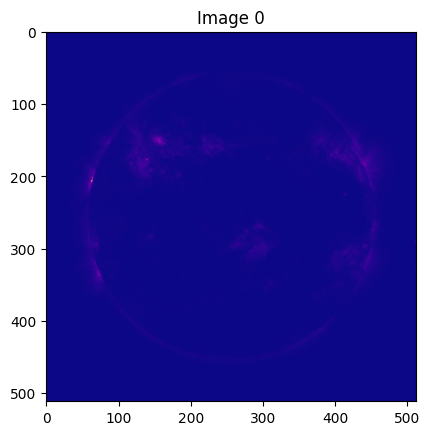

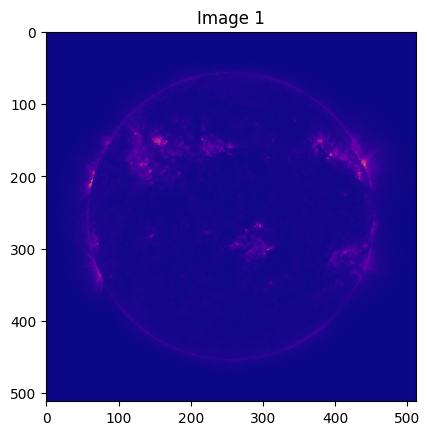

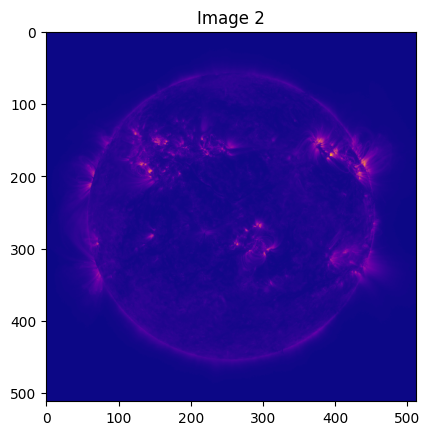

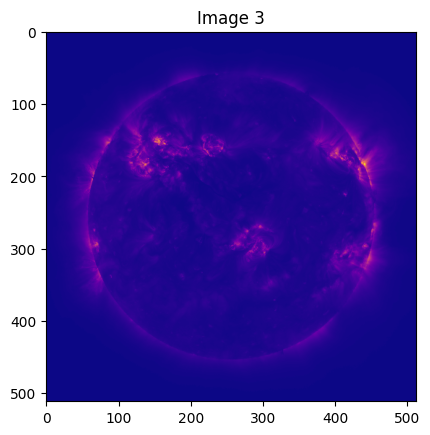

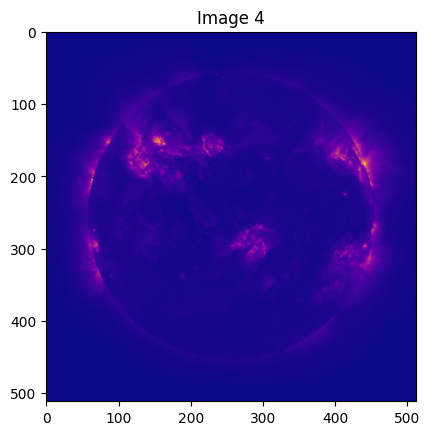

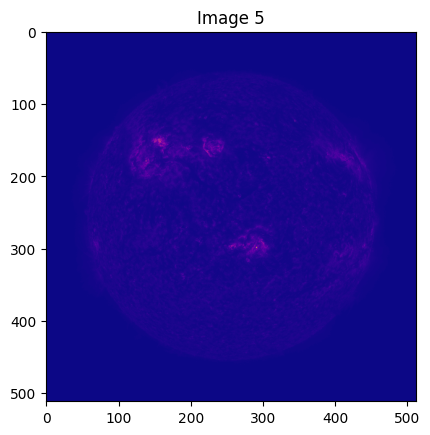

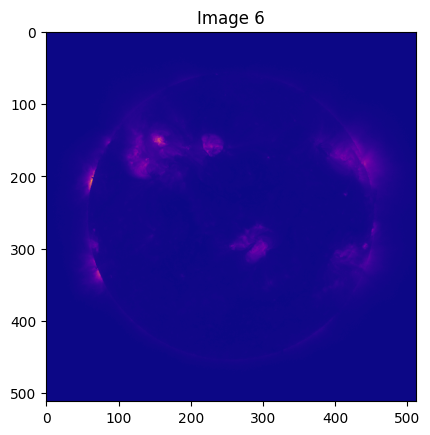

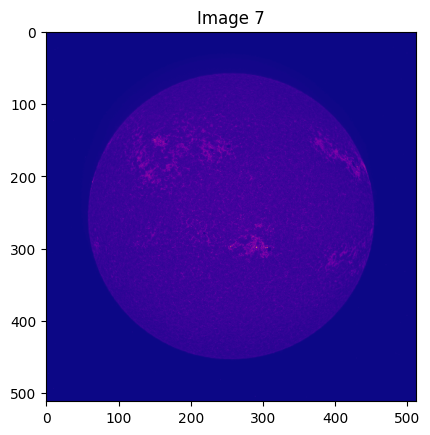

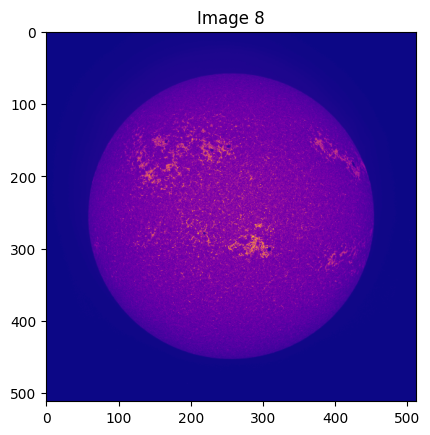

In [ ]:
for i in range(9):
  plt.imsave("vis_%d.png" % i,data[:,:,i],cmap='plasma')

  plt.figure()
  plt.imshow(data[:,:,i],cmap='plasma')
  plt.title("Image %d" % i)
  plt.show()

### Section 3.1: Images with a wide range of values

In [ ]:
# load 'mysterydata2.npy' and visualize
data2 = np.load("mysterydata2.npy")
print(data2.shape)
print(data2.dtype)
print(data2)

# apply non linear correction to (data)
data2_nlc = np.log1p(data2)

# save images using plt.imsave()
plt.imsave("vis2_0.png", data2_nlc[:,:,0])
plt.imsave("vis2_1.png", data2_nlc[:,:,1])

(512, 512, 9)
uint16
[[[  0   0   0 ...   1   0   1]
  [  0  12   0 ...   0   0   1]
  [  0   0   0 ...   0   0   1]
  ...
  [  0  51   0 ...   0   0   0]
  [  0   0   0 ...   0   0   0]
  [  0   0   0 ...   0   0   0]]

 [[  0   0   0 ...   0   0   2]
  [  0   0   0 ...   0   0   1]
  [  0  64   0 ...   0   0   0]
  ...
  [  0   0   0 ...   0   0   0]
  [  0   0   0 ...   0   0   0]
  [  0  64   0 ...   0   0   0]]

 [[  0 128   0 ...   0   0   1]
  [  0  51   0 ...   0   0   1]
  [  0 102   0 ...   0   0   1]
  ...
  [  0   0   0 ...   0   0   0]
  [  0  12   0 ...   0   0   0]
  [  0  25   0 ...   0   0   0]]

 ...

 [[  0 192   0 ...   0   0   0]
  [  0   0   0 ...   0   0   0]
  [  0   0   0 ...   0   0   0]
  ...
  [  0   0   0 ...   0   0   0]
  [  0  89   0 ...   0   0   0]
  [  0  64   0 ...   0   0   0]]

 [[  0   0   0 ...   0   0   0]
  [  0   0   0 ...   0   0   0]
  [  0   0   0 ...   0   0   0]
  ...
  [  0  12   0 ...   0   0   0]
  [  0   0   0 ...   0   0   0]
  [  0 

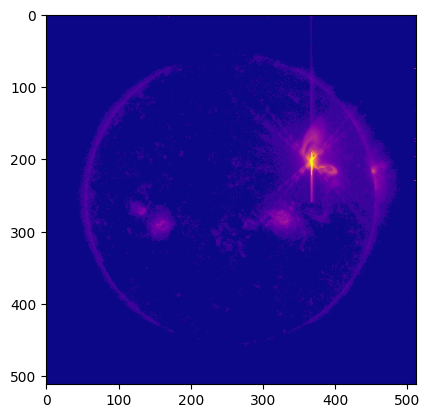

In [ ]:
# Visualise image 1 here
plt.imshow(data2_nlc[:,:,0], cmap='plasma')

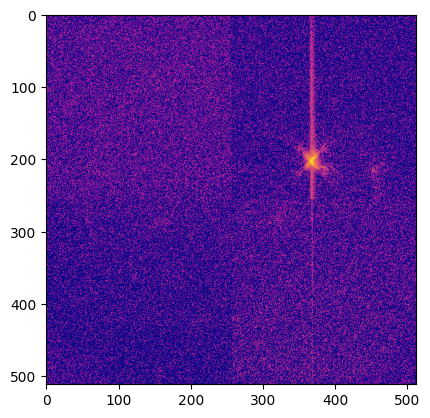

In [ ]:
# Visualise image 2 here
plt.imshow(data2_nlc[:,:,1], cmap='plasma')

### Section 3.2: Images that screw up and knowing your limits

In [ ]:
data3 = np.load("mysterydata3.npy")
for i in range(9):
  plt.imsave("vis3_%d.png" % i,data3[:,:,i])

In [ ]:
np.mean(np.isfinite(data3))

np.float64(0.6824828253851997)

In [ ]:
np.sum(~np.isfinite(data3))

np.int64(749117)

In [ ]:
# Determining the right range (use np.nanmin,np.nanmax)
# plt.imsave using the right range for the visualization.
# Refer to the documentation for plt.imsave.
vmin0 = np.nanmin(data3[:,:,0])
vmax0 = np.nanmax(data3[:,:,0])
vmin1 = np.nanmin(data3[:,:,1])
vmax1 = np.nanmax(data3[:,:,1])

plt.imsave("vis3_0.png", data3[:,:,0], vmin=vmin0, vmax=vmax0)
plt.imsave("vis3_1.png", data3[:,:,1], vmin=vmin1, vmax=vmax1)

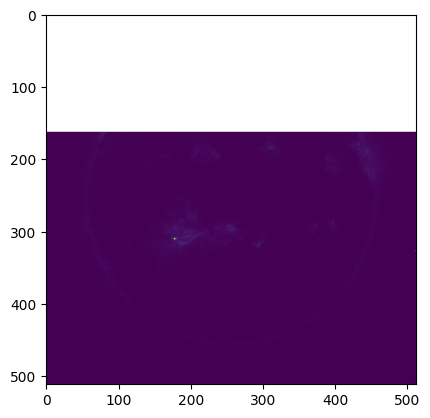

In [ ]:
# Visualize image 1 here
plt.imshow(data3[:,:,0], vmin=vmin0, vmax=vmax0)

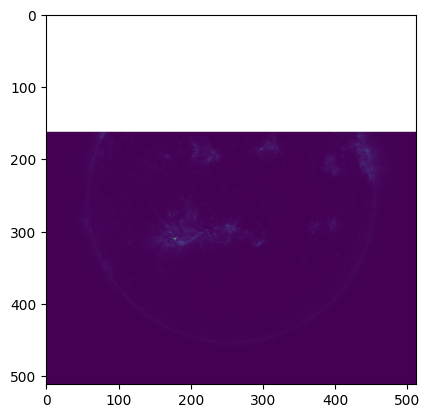

In [ ]:
# Visualize image 2 here
plt.imshow(data3[:,:,1], vmin=vmin1, vmax=vmax1)

### Section 3.3: Rolling your own plt.imsave

In [ ]:
def colormapArray(X, colors):
    """
    Basically plt.imsave but return a matrix instead

    Given:
        a HxW matrix X
        a Nx3 color map of colors in [0,1] [R,G,B]
    Outputs:
        a HxW uint8 image using the given colormap. See the Bewares
    """

    finite = np.isfinite(X)

    if (not np.any(finite)):
        return np.zeros((X.shape[0], X.shape[1], 3), dtype=np.uint8) # all-black

    N = np.zeros((X.shape[0], X.shape[1]))
    vmin = np.min(X[finite])
    vmax = np.max(X[finite])

    if (vmax != vmin):
        N[finite] = (X[finite] - vmin) / (vmax - vmin)

    i = ((len(colors) - 1) * N).astype(int)
    return (colors[i] * 255).astype(np.uint8)

### Section 3.4: Visualize mysterydata4

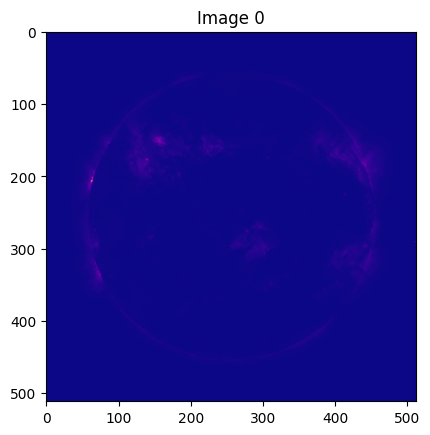

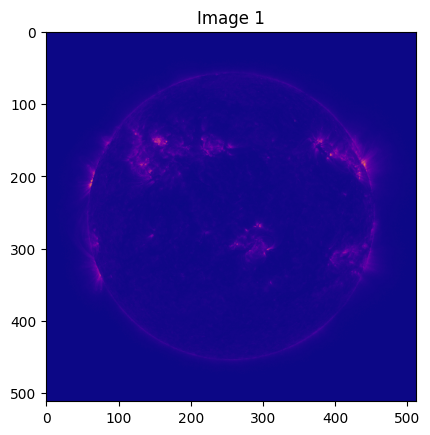

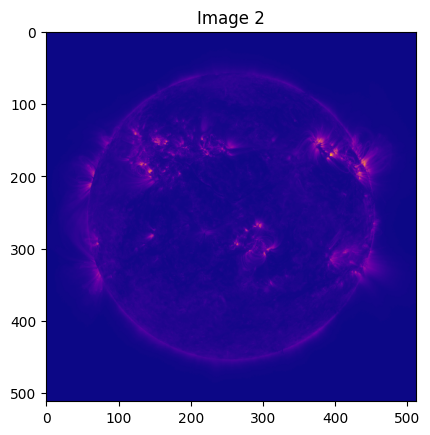

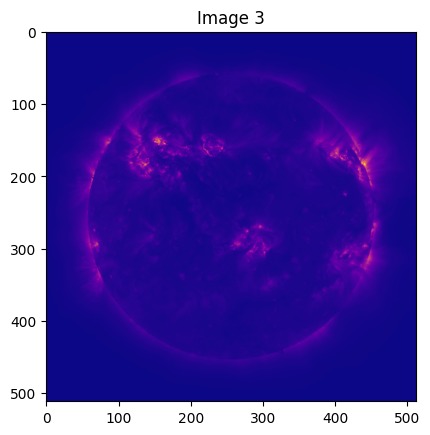

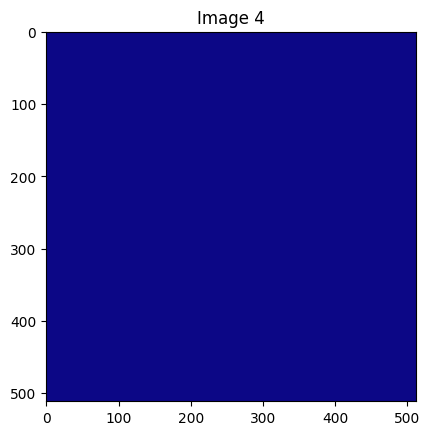

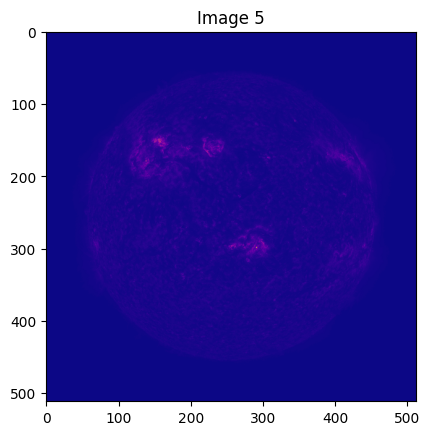

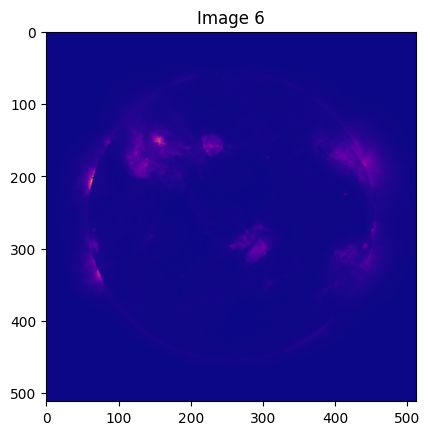

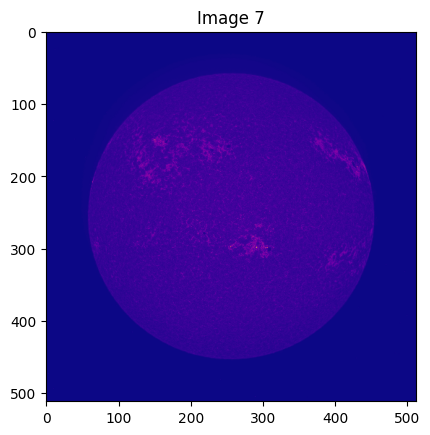

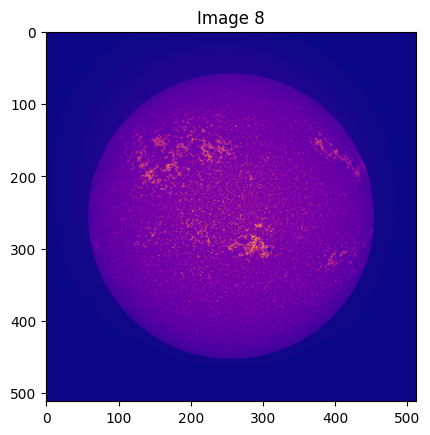

In [ ]:
# Visualize mysterydata4.npy using your system
# Put all nine images
data4 = np.load("mysterydata4.npy")

for i in range(9):
  cma = colormapArray(data4[:,:,i], colors)
  plt.imsave("vis4_%d.png" % i,cma)

  plt.figure()
  plt.imshow(cma)
  plt.title("Image %d" % i)
  plt.show()

### Optional PDF export
Use Jupyter's **Save and Export Notebook As** menu, or Colab's **File → Print**. PDF export is separate from running the project and requires no Drive authorization.
